# Dự đoán hiệu suất xe hơi

## 1. Import libraries

In [15]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F 
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
SEED = 59
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

## 2. Read dataset

In [16]:
dataset_path = "./data/[Data]_Ex1_Auto_MPG_data.csv"
dataset = pd.read_csv(dataset_path)
dataset.head()

,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Europe,Japan,USA
0,18.0,8,307.0,130.0,3504.0,12.0,70,0,0,1
1,15.0,8,350.0,165.0,3693.0,11.5,70,0,0,1
2,18.0,8,318.0,150.0,3436.0,11.0,70,0,0,1
3,16.0,8,304.0,150.0,3433.0,12.0,70,0,0,1
4,17.0,8,302.0,140.0,3449.0,10.5,70,0,0,1


## 3. Preprocessing data

### 3.1. X, y split

In [17]:
X = dataset.drop(columns=["MPG"]).values
y = dataset["MPG"].values

### 3.2. Train/val/test split

In [18]:
val_size = 0.2
test_size = 0.125
is_shuffle = True

X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.float32)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, 
    test_size=val_size,
    random_state=SEED,
    shuffle=is_shuffle
)

X_train, X_test, y_train, y_test = train_test_split(
    X_train, y_train,
    test_size=test_size,
    random_state=SEED,
    shuffle=is_shuffle
)

In [1]:
print(f"Number of training samples: {X_train.shape[0]}")
print(f"Number of validation samples: {X_val.shape[0]}")
print(f"Number of test samples: {X_test.shape[0]}")

NameError: name 'X_train' is not defined

### 3.3. Data normalization

In [20]:
normalization = StandardScaler()

# Fit StandardScaler on X_train only; transform X_train, X_val and X_test
X_train = normalization.fit_transform(X_train)
X_test = normalization.transform(X_test)
X_val = normalization.transform(X_val)


## 4. Create PyTorch DataLoader

In [21]:
class CustomDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    
    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

In [ ]:
train_dataset = CustomDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=is_shuffle)
val_dataset = CustomDataset(X_val, y_val)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_15500\3455071738.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.y = torch.tensor(y, dtype=torch.float32)


## 5. Build MPL Network

In [23]:
class MLP(nn.Module):
    def __init__(self, input_dims, hidden_dims, output_dims):
        super().__init__()
        self.liner1 = nn.Linear(input_dims, hidden_dims)
        self.liner2 = nn.Linear(hidden_dims, hidden_dims)
        self.output = nn.Linear(hidden_dims, output_dims)

    def forward(self, x):
        x = F.relu(self.liner1(x))
        x = F.relu(self.liner2(x))
        out = self.output(x)
        return out.squeeze(1)

In [24]:
model = MLP(input_dims=X_train.shape[1], output_dims=1, hidden_dims=64).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

## 6. Training

In [25]:
def r_squared(y_true, y_pred):
    y_true = torch.tensor(y_true)
    y_pred = torch.tensor(y_pred)
    ss_res = torch.sum((y_true - y_pred)**2)
    y_mean = torch.mean(y_true)
    ss_tot = torch.sum((y_true - y_mean)**2)
    return 1 - ss_res/ss_tot

In [26]:
epochs = 100
train_losses = []
val_losses = []
train_r2 = []
val_r2 = []
for epoch in range(epochs):
    train_loss = 0.0
    train_target = []
    val_target = []
    train_predict = []
    val_predict = []
    model.train()
    for X_samples, y_samples in train_loader:
        X_samples = X_samples.to(device)
        y_samples = y_samples.to(device)
        optimizer.zero_grad()
        outputs = model(X_samples)
        train_predict += outputs.tolist()
        train_target += y_samples.tolist()
        loss = criterion(outputs, y_samples)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    train_loss /= len(train_loader)
    train_losses.append(train_loss)
    train_r2.append(r_squared(train_target, train_predict))
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for X_samples, y_samples in val_loader:
            X_samples = X_samples.to(device)
            y_samples = y_samples.to(device)
            outputs = model(X_samples)
            val_predict += outputs.tolist()
            val_target += y_samples.tolist()
            loss = criterion(outputs, y_samples)
            val_loss += loss.item()
    val_loss /= len(val_loader)
    val_losses.append(val_loss)
    val_r2.append(r_squared(val_target, val_predict))
    print(f"\nEPOCH {epoch + 1}: \tTraining loss: {train_loss:.3f}\tValidation loss: {val_loss:.3f}")



EPOCH 1: 	Training loss: 282.769	Validation loss: 95.336

EPOCH 2: 	Training loss: 221.930	Validation loss: 14.702

EPOCH 3: 	Training loss: 64.709	Validation loss: 61.326

EPOCH 4: 	Training loss: 56.289	Validation loss: 11.455

EPOCH 5: 	Training loss: 15.971	Validation loss: 28.501

EPOCH 6: 	Training loss: 13.478	Validation loss: 5.629

EPOCH 7: 	Training loss: 16.996	Validation loss: 31.467

EPOCH 8: 	Training loss: 19.224	Validation loss: 24.410

EPOCH 9: 	Training loss: 15.799	Validation loss: 10.714

EPOCH 10: 	Training loss: 19.927	Validation loss: 13.430

EPOCH 11: 	Training loss: 17.391	Validation loss: 7.864

EPOCH 12: 	Training loss: 11.310	Validation loss: 41.189

EPOCH 13: 	Training loss: 18.784	Validation loss: 13.625

EPOCH 14: 	Training loss: 7.906	Validation loss: 16.750

EPOCH 15: 	Training loss: 9.398	Validation loss: 6.379

EPOCH 16: 	Training loss: 7.601	Validation loss: 5.139

EPOCH 17: 	Training loss: 6.491	Validation loss: 5.136

EPOCH 18: 	Training loss: 7.3

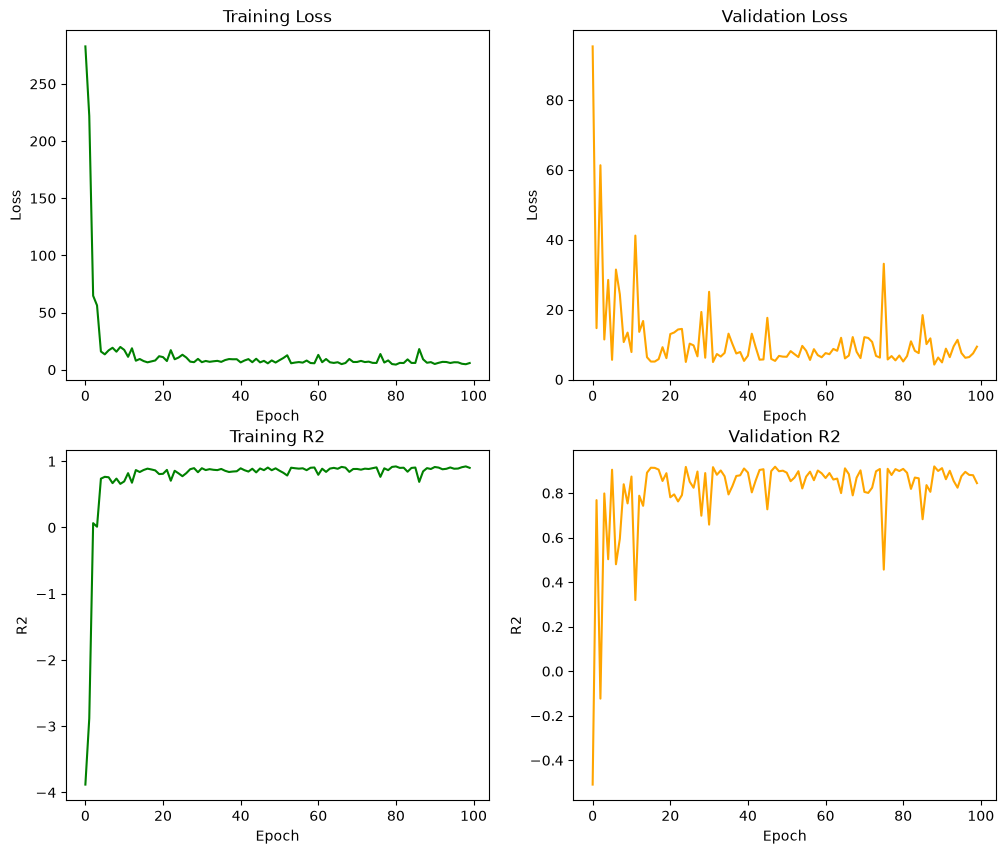

In [27]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
ax[0, 0].plot(train_losses, color='green')
ax[0, 0].set(xlabel='Epoch', ylabel='Loss')
ax[0, 0].set_title('Training Loss')

ax[0, 1].plot(val_losses, color='orange')
ax[0, 1].set(xlabel='Epoch', ylabel='Loss')
ax[0, 1].set_title('Validation Loss')

ax[1, 0].plot(train_r2, color='green')
ax[1, 0].set(xlabel='Epoch', ylabel='R2')
ax[1, 0].set_title('Training R2')

ax[1, 1].plot(val_r2, color='orange')
ax[1, 1].set(xlabel='Epoch', ylabel='R2')
ax[1, 1].set_title('Validation R2')

plt.show()

## 7. Evaluation

In [29]:
model.eval()
with torch.no_grad():
    X_val_t = torch.tensor(X_val, dtype=torch.float32).to(device)
    y_hat = model(X_val_t)
    val_set_r2 = r_squared(y_val.tolist(), y_hat.tolist())
    print("Evaluation on validation set:")
    print(f"R2: {val_set_r2.item():.4f}")


Evaluation on validation set:
R2: 0.8448


In [ ]:
model.eval()
with torch.no_grad():
    X_test_t = torch.tensor(X_test, dtype=torch.float32).to(device)
    y_hat = model(X_test_t)
    test_set_r2 = r_squared(y_val.tolist(), y_hat.tolist())
    print("Evaluation on validation set:")
    print(f"R2: {test_set_r2.item():.4f}")